In [1]:
import numpy as np
def stable_softmax(x, axis=-1):
    x_max = np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x - x_max)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

def scaled_dot_product_attention(Q, K, V):
    d_k = Q.shape[-1]
    scores = np.matmul(Q, K.swapaxes(-2, -1)) / np.sqrt(d_k)
    attention_weights = stable_softmax(scores, axis=-1)
    context = np.matmul(attention_weights, V)
    return scores, attention_weights, context
x_large = np.array([1000.0, 1001.0, 1002.0])
print("Test numerical stability:")
with np.errstate(all='raise'):
    try:
        print("Softmax thông thường:", np.exp(x_large) / np.sum(np.exp(x_large)))
    except FloatingPointError:
        print("Tràn số xảy ra với np.exp! (Đã bắt được lỗi)")

# Chạy hàm stable_softmax để thấy kết quả chuẩn xác
print("Stable Softmax kết quả:", stable_softmax(x_large))

Test numerical stability:
Tràn số xảy ra với np.exp! (Đã bắt được lỗi)
Stable Softmax kết quả: [0.09003057 0.24472847 0.66524096]


Q matrix:
 [[0.55 0.6 ]
 [0.25 1.24]
 [0.71 1.12]]
K matrix:
 [[0.7  0.65]
 [0.42 1.11]
 [0.94 1.13]]
Attention Matrix (A):
 [[0.291  0.3173 0.3917]
 [0.2491 0.3549 0.396 ]
 [0.2564 0.3207 0.423 ]]
Context Matrix (C):
 [[1.0805 1.0295]
 [1.0732 1.0628]
 [1.0922 1.0498]]


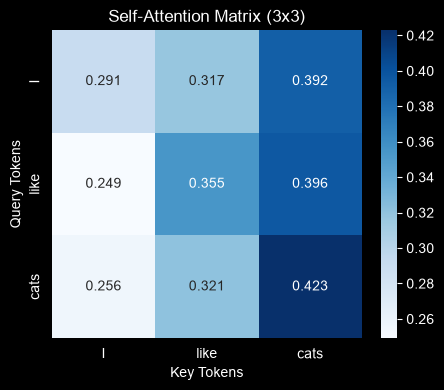

In [2]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
tokens_3 = ["I", "like", "cats"]
X = np.array([
    [1.0, 0.5],  # "I"
    [0.2, 1.5],  # "like"
    [1.2, 1.1]   # "cats"
])

# W_Q, W_K, W_V
W_Q = np.array([[0.5, 0.2], [0.1, 0.8]])
W_K = np.array([[0.6, 0.3], [0.2, 0.7]])
W_V = np.array([[0.8, 0.1], [0.4, 0.9]])

Q = X @ W_Q
K = X @ W_K
V = X @ W_V

scores_sa, A_sa, Context_sa = scaled_dot_product_attention(Q, K, V)

print("Q matrix:\n", np.round(Q, 3))
print("K matrix:\n", np.round(K, 3))
print("Attention Matrix (A):\n", np.round(A_sa, 4))
print("Context Matrix (C):\n", np.round(Context_sa, 4))

# Visualize Self-Attention Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(A_sa, annot=True, fmt=".3f", xticklabels=tokens_3, yticklabels=tokens_3, cmap="Blues")
plt.title("Self-Attention Matrix (3x3)")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.show()

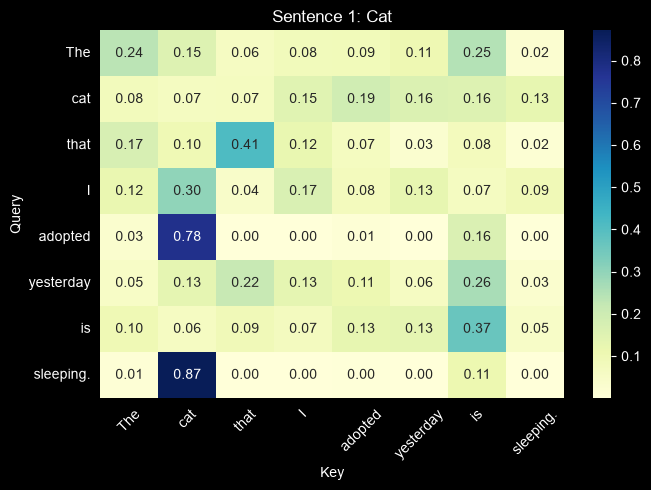

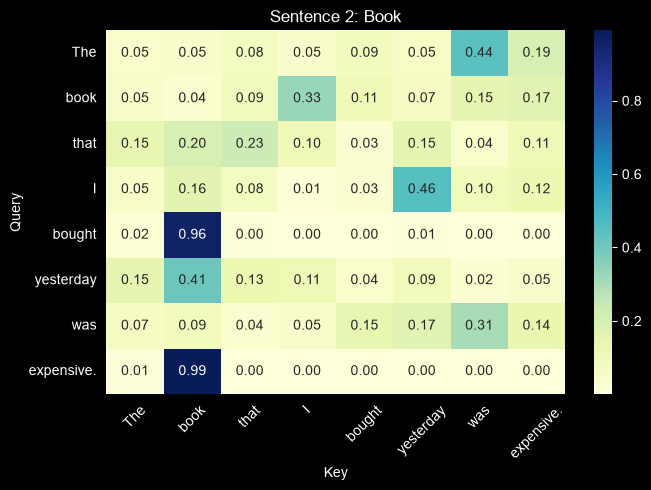

In [3]:
def plot_sentence_attention(sentence, title):
    toks = sentence.split()
    N = len(toks)
    np.random.seed(sum(map(ord, sentence)))

    # Giả lập ma trận Q, K để thể hiện mối quan hệ cú pháp
    Q = np.random.randn(N, 8)
    K = np.random.randn(N, 8)

    # Tạo liên kết giữa chủ ngữ và vị ngữ (cat -> sleeping, book -> expensive)
    if "cat" in toks and "sleeping." in toks:
        Q[toks.index("sleeping."), :] = K[toks.index("cat"), :] * 2.0
        Q[toks.index("adopted"), :] = K[toks.index("cat"), :] * 1.5
    if "book" in toks and "expensive." in toks:
        Q[toks.index("expensive."), :] = K[toks.index("book"), :] * 2.0
        Q[toks.index("bought"), :] = K[toks.index("book"), :] * 1.5

    _, A, _ = scaled_dot_product_attention(Q, K, K)

    plt.figure(figsize=(7, 5))
    sns.heatmap(A, annot=True, fmt=".2f", xticklabels=toks, yticklabels=toks, cmap="YlGnBu")
    plt.title(title)
    plt.xlabel("Key")
    plt.ylabel("Query")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

plot_sentence_attention("The cat that I adopted yesterday is sleeping.", "Sentence 1: Cat")
plot_sentence_attention("The book that I bought yesterday was expensive.", "Sentence 2: Book")

**Câu hỏi:** *Attention visualization có chứng minh mô hình đang thực hiện reasoning hay "hiểu ngữ pháp" không?*

**Trả lời:** **Không hoàn toàn.**

Attention pattern chỉ thể hiện trọng số phân bố xác suất dựa trên sự tương đồng không gian biểu diễn toán học giữa Query ($Q$) và Key ($K$) nhằm tối ưu hóa (giảm) loss function.

* **Sự tương quan dữ liệu (Correlation):** Trọng số Attention cung cấp bằng chứng về mối liên hệ thống kê giữa các vector biểu diễn.
* **Không phải lý luận logic (Causality):** Nó không tự động đại diện cho khả năng lý luận logic (causal reasoning) hay tri thức cú pháp thực sự theo góc nhìn của con người.

In [8]:
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score
from IPython.display import display

# Set seed để tái lập kết quả
torch.manual_seed(42)
np.random.seed(42)

# --- 1. TẠO TẬP DỮ LIỆU GIẢ LẬP (SYNTHETIC DATASET) ---
vocab_size = 1000
embed_dim = 64
seq_len = 30
num_samples = 1000
batch_size = 32

# Tạo dữ liệu ngẫu nhiên (80% train, 20% test)
X = torch.randint(0, vocab_size, (num_samples, seq_len))
y = torch.randint(0, 2, (num_samples,))

train_data = TensorDataset(X[:800], y[:800])
test_data = TensorDataset(X[800:], y[800:])

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

# --- 2. ĐỊNH NGHĨA MÔ HÌNH LSTM ---
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 2)

    def forward(self, x):
        emb = self.embedding(x)
        _, (hn, _) = self.lstm(emb)  # Lấy final hidden state h_T
        out = self.fc(hn.squeeze(0))
        return out

# --- 3. ĐỊNH NGHĨA MÔ HÌNH ATTENTION ---
class AttentionClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.W_q = nn.Linear(embed_dim, embed_dim)
        self.W_k = nn.Linear(embed_dim, embed_dim)
        self.W_v = nn.Linear(embed_dim, embed_dim)
        self.fc = nn.Linear(embed_dim, 2)

    def forward(self, x):
        emb = self.embedding(x)  # (batch, seq_len, embed_dim)
        Q = self.W_q(emb)
        K = self.W_k(emb)
        V = self.W_v(emb)

        # Scaled Dot-Product Self-Attention
        d_k = Q.shape[-1]
        scores = torch.bmm(Q, K.transpose(1, 2)) / (d_k ** 0.5)
        attn_weights = torch.softmax(scores, dim=-1)

        # Context representation (lấy trung bình context vectors)
        context = torch.bmm(attn_weights, V).mean(dim=1)
        out = self.fc(context)
        return out

# --- 4. HÀM HUẤN LUYỆN VÀ ĐÁNH GIÁ ---
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def train_and_evaluate(model, train_loader, test_loader, epochs=10):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Đo thời gian huấn luyện
    start_time = time.time()
    model.train()
    for epoch in range(epochs):
        for batch_x, batch_y in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()
    training_time = time.time() - start_time

    # Đánh giá trên tập Test
    model.eval()
    all_preds = []
    all_targets = []
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            outputs = model(batch_x)
            preds = torch.argmax(outputs, dim=1)
            # SỬA TẠI ĐÂY: Dùng .tolist() thay vì .cpu().numpy()
            all_preds.extend(preds.cpu().tolist())
            all_targets.extend(batch_y.cpu().tolist())

    acc = accuracy_score(all_targets, all_preds)
    f1 = f1_score(all_targets, all_preds, average='macro')
    params = count_parameters(model)

    return acc, f1, training_time, params
# --- 5. CHẠY THỰC NGHIỆM VÀ XUẤT BẢNG ---
models = {
    "LSTM": LSTMClassifier(vocab_size, embed_dim),
    "Attention": AttentionClassifier(vocab_size, embed_dim)
}

results = []
for name, model in models.items():
    acc, f1, train_time, params = train_and_evaluate(model, train_loader, test_loader, epochs=10)
    results.append({
        "Model": name,
        "Accuracy": f"{acc * 100:.2f}%",
        "F1": f"{f1:.4f}",
        "Training time": f"{train_time:.3f} s",
        "Parameters": f"{params:,}"
    })

# Tạo DataFrame và hiển thị dạng bảng
df_results = pd.DataFrame(results)

print("=== EXPERIMENT 4: QUANTITATIVE EVALUATION TABLE ===")
display(df_results)

=== EXPERIMENT 4: QUANTITATIVE EVALUATION TABLE ===


,Model,Accuracy,F1,Training time,Parameters
0,LSTM,45.00%,0.4486,1.816 s,"97,410"
1,Attention,50.50%,0.5035,0.773 s,"76,610"


 Sequence Length (T) Attention Matrix Size  Total Elements (T^2)  Memory (Float32 MB)
                  10               10 x 10                   100             0.000381
                 100             100 x 100                 10000             0.038147
                 500             500 x 500                250000             0.953674
                1000           1000 x 1000               1000000             3.814697
               10000         10000 x 10000             100000000           381.469727


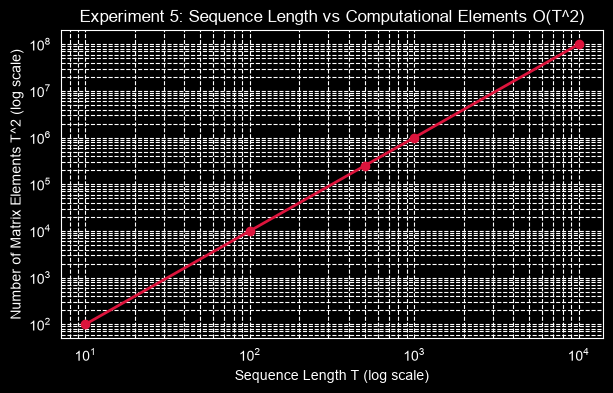

In [11]:
lengths = [10, 100, 500, 1000, 10000]
matrix_elements = [T**2 for T in lengths]

df_cost = pd.DataFrame({
    "Sequence Length (T)": lengths,
    "Attention Matrix Size": [f"{T} x {T}" for T in lengths],
    "Total Elements (T^2)": matrix_elements,
    "Memory (Float32 MB)": [ (T**2 * 4) / (1024**2) for T in lengths]
})
print(df_cost.to_string(index=False))

plt.figure(figsize=(7, 4))
plt.plot(lengths, matrix_elements, marker='o', color='crimson', linewidth=2)
plt.xscale('log')
plt.yscale('log')
plt.title("Experiment 5: Sequence Length vs Computational Elements O(T^2)")
plt.xlabel("Sequence Length T (log scale)")
plt.ylabel("Number of Matrix Elements T^2 (log scale)")
plt.grid(True, which="both", ls="--")
plt.show()

**Câu hỏi:** Tại sao Self-Attention gặp vấn đề chi phí tính toán khi sequence rất dài?

**Trả lời:** Do ma trận attention có kích thước $T \times T$, bộ nhớ và số phép tính nhân ma trận tăng theo cấp số nhân bậc hai $O(T^2)$.

Khi $T = 10,000$, ma trận tạo ra 100 triệu phần tử (~400MB chỉ cho một head attention của một sample), gây ra tình trạng bùng nổ bộ nhớ GPU (*Out-Of-Memory*).